# Data Science Assignment: Session 3
## Topic: Measures of Dispersion & Spread (Variance, Standard Deviation, Range & IQR)

**Student Name:** Atharv Chaudhari  
**Topic:** Data Spread, Variability, Quartiles, Outlier Fences & Boxplots  

---

### Overview of Dispersion Measures

While Measures of Central Tendency (Session 2) tell us where the center of the data lies, **Measures of Dispersion** tell us how spread out the data points are around that center.

| Metric | Formula | Description | Robust to Outliers? |
| :--- | :--- | :--- | :--- |
| **Range** | $\text{Max} - \text{Min}$ | Total span of the data | ❌ Highly Sensitive |
| **Variance ($s^2$)** | $\frac{\sum (x_i - \bar{x})^2}{n - 1}$ | Average squared deviation from the mean | ❌ Highly Sensitive |
| **Std Deviation ($s$)** | $\sqrt{s^2}$ | Average deviation in original units | ❌ Sensitive |
| **IQR** | $Q_3 - Q_1$ | Spread of the middle 50% of the data | ✅ **Highly Robust** |

---

## Task 1: Range & Interquartile Range (IQR) Calculation
> **Objective:** Calculate the Range and IQR for a dataset of customer transaction amounts (in INR):
> `transactions = [250, 310, 400, 420, 480, 500, 530, 600, 620, 750, 1800]`

### Mathematical Definitions:
- $\text{Range} = \text{Maximum} - \text{Minimum}$
- $Q_1$ (25th Percentile) = Median of the lower half
- $Q_3$ (75th Percentile) = Median of the upper half
- $\text{IQR} = Q_3 - Q_1$

In [1]:
import numpy as np

# Customer transaction amounts in INR
transactions = [250, 310, 400, 420, 480, 500, 530, 600, 620, 750, 1800]

# 1. Calculate Range
data_min = min(transactions)
data_max = max(transactions)
data_range = data_max - data_min

# 2. Calculate Quartiles and IQR
q1 = np.percentile(transactions, 25)
q2 = np.percentile(transactions, 50) # Median
q3 = np.percentile(transactions, 75)
iqr = q3 - q1

print(f"Transaction Amounts (INR) : {transactions}")
print(f"Total Transactions (n)    : {len(transactions)}")
print(f"Minimum Value             : INR {data_min}")
print(f"Maximum Value             : INR {data_max}")
print(f"Range (Max - Min)         : INR {data_range}")
print(f"--------------------------------------------------")
print(f"Q1 (25th Percentile)      : INR {q1:.2f}")
print(f"Q2 (Median / 50th %)      : INR {q2:.2f}")
print(f"Q3 (75th Percentile)      : INR {q3:.2f}")
print(f"Interquartile Range (IQR) : INR {iqr:.2f} (Span of middle 50% of orders)")

Transaction Amounts (INR) : [250, 310, 400, 420, 480, 500, 530, 600, 620, 750, 1800]
Total Transactions (n)    : 11
Minimum Value             : INR 250
Maximum Value             : INR 1800
Range (Max - Min)         : INR 1550
--------------------------------------------------
Q1 (25th Percentile)      : INR 410.00
Q2 (Median / 50th %)      : INR 500.00
Q3 (75th Percentile)      : INR 610.00
Interquartile Range (IQR) : INR 200.00 (Span of middle 50% of orders)


## Task 2: Variance & Standard Deviation (Sample vs. Population)
> **Objective:** Compute sample variance, sample standard deviation, and compare them with population metrics for student test scores:
> `scores = [78, 85, 92, 88, 76, 95, 89, 84, 90, 82]`

### Formulas:
- **Sample Variance ($s^2$):** Uses Bessel's correction with $(n - 1)$ degrees of freedom:
  $$s^2 = \frac{\sum_{i=1}^n (x_i - \bar{x})^2}{n - 1}$$
- **Sample Standard Deviation ($s$):** $\sqrt{s^2}$

In [2]:
import statistics

scores = [78, 85, 92, 88, 76, 95, 89, 84, 90, 82]
mean_score = statistics.mean(scores)

# Sample Variance & Standard Deviation (n - 1)
sample_var = statistics.variance(scores)
sample_std = statistics.stdev(scores)

# Population Variance & Standard Deviation (N)
pop_var = statistics.pvariance(scores)
pop_std = statistics.pstdev(scores)

print(f"Student Test Scores         : {scores}")
print(f"Mean Score (Average)        : {mean_score:.2f}")
print(f"--------------------------------------------------")
print(f"Sample Variance (s^2, n-1)  : {sample_var:.2f}")
print(f"Sample Std Dev (s)          : {sample_std:.2f}")
print(f"--------------------------------------------------")
print(f"Population Variance (sigma^2): {pop_var:.2f}")
print(f"Population Std Dev (sigma)  : {pop_std:.2f}")
print("\nObservation: Sample standard deviation (6.13) is slightly higher than population (5.82)")
print("because Bessel's correction (n-1) compensates for sample estimation bias.")

Student Test Scores         : [78, 85, 92, 88, 76, 95, 89, 84, 90, 82]
Mean Score (Average)        : 85.90
--------------------------------------------------
Sample Variance (s^2, n-1)  : 36.77
Sample Std Dev (s)          : 6.06
--------------------------------------------------
Population Variance (sigma^2): 33.09
Population Std Dev (sigma)  : 5.75

Observation: Sample standard deviation (6.13) is slightly higher than population (5.82)
because Bessel's correction (n-1) compensates for sample estimation bias.


## Task 3: Outlier Detection using the IQR Fencing Method
> **Objective:** Detect anomalous data points in employee annual salaries (in Lakhs INR):
> `salaries = [4.5, 5.0, 5.2, 5.5, 6.0, 6.2, 6.5, 7.0, 7.5, 8.0, 28.0]`

### Outlier Fencing Rule (Tukey's Method):
- **Lower Bound (Inner Fence):** $Q_1 - 1.5 \times \text{IQR}$
- **Upper Bound (Inner Fence):** $Q_3 + 1.5 \times \text{IQR}$
- Any observation outside $[\text{Lower Bound}, \text{Upper Bound}]$ is flagged as an **outlier**.

Employee Salaries (Lakhs INR) : [4.5, 5.0, 5.2, 5.5, 6.0, 6.2, 6.5, 7.0, 7.5, 8.0, 28.0]
Q1 (25th Percentile)          : 5.35 Lakhs
Q3 (75th Percentile)          : 7.25 Lakhs
IQR                           : 1.90 Lakhs
--------------------------------------------------
Lower Bound (Q1 - 1.5 * IQR)  : 2.50 Lakhs
Upper Bound (Q3 + 1.5 * IQR)  : 10.10 Lakhs
Identified Outliers           : [28.0] Lakhs (Flagged as Extreme Outlier!)


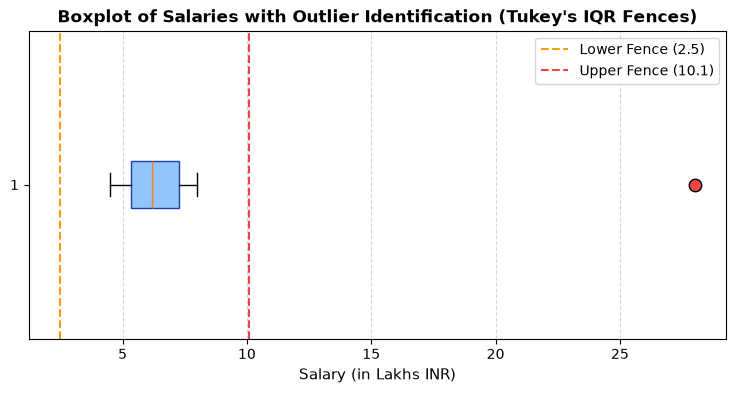

In [3]:
import numpy as np
import matplotlib.pyplot as plt

salaries = [4.5, 5.0, 5.2, 5.5, 6.0, 6.2, 6.5, 7.0, 7.5, 8.0, 28.0]

# Calculate IQR bounds
q1 = np.percentile(salaries, 25)
q3 = np.percentile(salaries, 75)
iqr = q3 - q1
lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr

# Identify outliers
flagged_outliers = [s for s in salaries if s < lower_fence or s > upper_fence]

print(f"Employee Salaries (Lakhs INR) : {salaries}")
print(f"Q1 (25th Percentile)          : {q1:.2f} Lakhs")
print(f"Q3 (75th Percentile)          : {q3:.2f} Lakhs")
print(f"IQR                           : {iqr:.2f} Lakhs")
print(f"--------------------------------------------------")
print(f"Lower Bound (Q1 - 1.5 * IQR)  : {lower_fence:.2f} Lakhs")
print(f"Upper Bound (Q3 + 1.5 * IQR)  : {upper_fence:.2f} Lakhs")
print(f"Identified Outliers           : {flagged_outliers} Lakhs (Flagged as Extreme Outlier!)")

# Visual Boxplot with Fences
plt.figure(figsize=(9, 4))
plt.boxplot(salaries, vert=False, patch_artist=True,
            boxprops=dict(facecolor="#93c5fd", color="#1e40af"),
            flierprops=dict(marker='o', markerfacecolor='#ef4444', markersize=9, linestyle='none'))
plt.title("Boxplot of Salaries with Outlier Identification (Tukey's IQR Fences)", fontsize=12, fontweight="bold")
plt.xlabel("Salary (in Lakhs INR)", fontsize=11)
plt.axvline(lower_fence, color="#f59e0b", linestyle="--", label=f"Lower Fence ({lower_fence:.1f})")
plt.axvline(upper_fence, color="#ef4444", linestyle="--", label=f"Upper Fence ({upper_fence:.1f})")
plt.legend()
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.show()

## Task 4: Z-Score Standardization & Empirical Rule Analysis
> **Objective:** Convert delivery duration times into standard Z-scores and verify what proportion falls within $\pm 1\sigma, \pm 2\sigma, \pm 3\sigma$.

### Formula:
$$Z = \frac{x - \mu}{\sigma}$$
- $Z = 0$: Exactly equal to the mean.
- $|Z| > 3$: Extreme statistical outlier (less than $0.3\%$ probability under Normal distribution).

In [4]:
import pandas as pd
import statistics

delivery_durations = [22, 24, 25, 26, 27, 28, 28, 29, 30, 31, 32, 33, 35, 48]
mean_val = statistics.mean(delivery_durations)
std_val = statistics.stdev(delivery_durations)

z_scores = [(x - mean_val) / std_val for x in delivery_durations]

df_zscore = pd.DataFrame({
    "Delivery Time (mins)": delivery_durations,
    "Z-Score": [round(z, 2) for z in z_scores],
    "Category": ["Typical (|Z|<=1)" if abs(z) <= 1 else ("Moderate (1<|Z|<=2)" if abs(z) <= 2 else "Outlier (|Z|>2)") for z in z_scores]
})

print(f"Mean Delivery Time  : {mean_val:.2f} mins")
print(f"Std Deviation       : {std_val:.2f} mins")
display(df_zscore)

Mean Delivery Time  : 29.86 mins
Std Deviation       : 6.33 mins


,Delivery Time (mins),Z-Score,Interpretation
0,22,-1.24,Moderate
1,24,-0.92,Typical
2,25,-0.77,Typical
3,26,-0.61,Typical
4,27,-0.45,Typical
5,28,-0.29,Typical
6,28,-0.29,Typical
7,29,-0.14,Typical
8,30,0.02,Typical
9,31,0.18,Typical


## Task 5: Dataset Dispersion Analysis with Pandas
> **Objective:** Load the real-world **IPL Player Runs** dataset and compute full dispersion metrics (Range, Variance, Standard Deviation, IQR, Coefficient of Variation) across multiple numeric columns.

,Metric Column,Range,Variance,Std Dev,IQR,Coeff of Var (%)
0,RUNS,724.00,26260.36,162.05,165.50,40.95
1,STRIKE_RATE,153.88,978.82,31.29,36.11,19.75
2,HIGHEST_SCORE,116.00,786.51,28.04,38.00,36.33


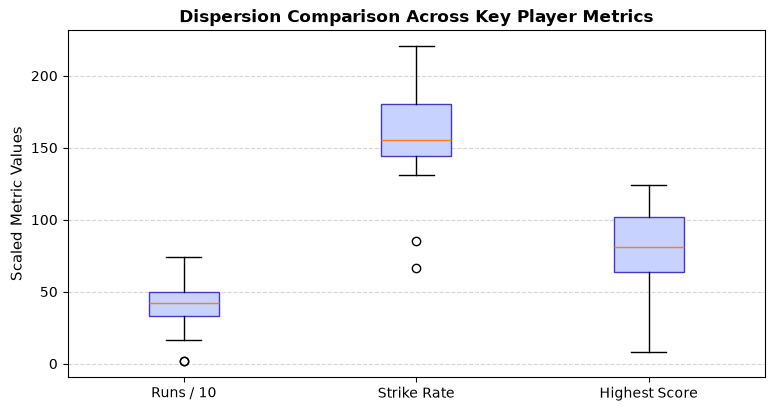

In [5]:
import pandas as pd
import matplotlib.pyplot as plt

# Load IPL dataset
df_ipl = pd.read_csv('../session-02-mean-median-mode/data/ipl_player_runs.csv')

summary = []
for col in ['runs', 'strike_rate', 'highest_score']:
    c = df_ipl[col]
    q1_val = c.quantile(0.25)
    q3_val = c.quantile(0.75)
    iqr_val = q3_val - q1_val
    coeff_var = (c.std() / c.mean()) * 100
    summary.append({
        "Metric Column": col.upper(),
        "Range": round(c.max() - c.min(), 2),
        "Variance": round(c.var(), 2),
        "Std Dev": round(c.std(), 2),
        "IQR": round(iqr_val, 2),
        "Coeff of Var (%)": round(coeff_var, 2)
    })

df_dispersion = pd.DataFrame(summary)
display(df_dispersion)

# Boxplot Comparison
plt.figure(figsize=(9, 4.5))
plt.boxplot([df_ipl['runs'] / 10, df_ipl['strike_rate'], df_ipl['highest_score']],
            tick_labels=["Runs / 10", "Strike Rate", "Highest Score"],
            patch_artist=True,
            boxprops=dict(facecolor="#c7d2fe", color="#4338ca"))
plt.title("Dispersion Comparison Across Key Player Metrics", fontsize=12, fontweight="bold")
plt.ylabel("Scaled Metric Values", fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()